KAVYASHREE ENG24CS0094 B1 25/08/2026 experiment 6:KNN

In [362]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
        
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [363]:
df=pd.read_csv('./diabetes (6).csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [364]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [365]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [366]:
df.shape

(768, 9)

In [367]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [368]:
df.duplicated().sum()

0

In [369]:
for column in df.columns:
    print(f'{column}: {df.loc[df[column] == 0, column].count()}')

Pregnancies: 111
Glucose: 5
BloodPressure: 35
SkinThickness: 227
Insulin: 374
BMI: 11
DiabetesPedigreeFunction: 0
Age: 0
Outcome: 500


In [370]:
#Replace zero by NaN by median
columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for column in columns:
    df[column] = df[column].replace(0, np.nan)

In [371]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


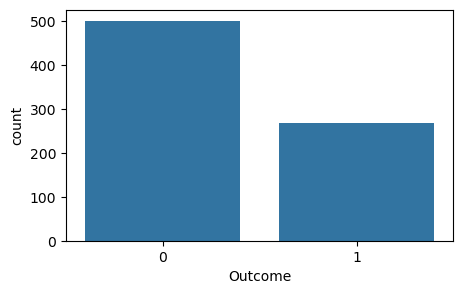

In [372]:
plt.figure(figsize=(5,3))
sns.countplot(data=df,x='Outcome')
plt.show()

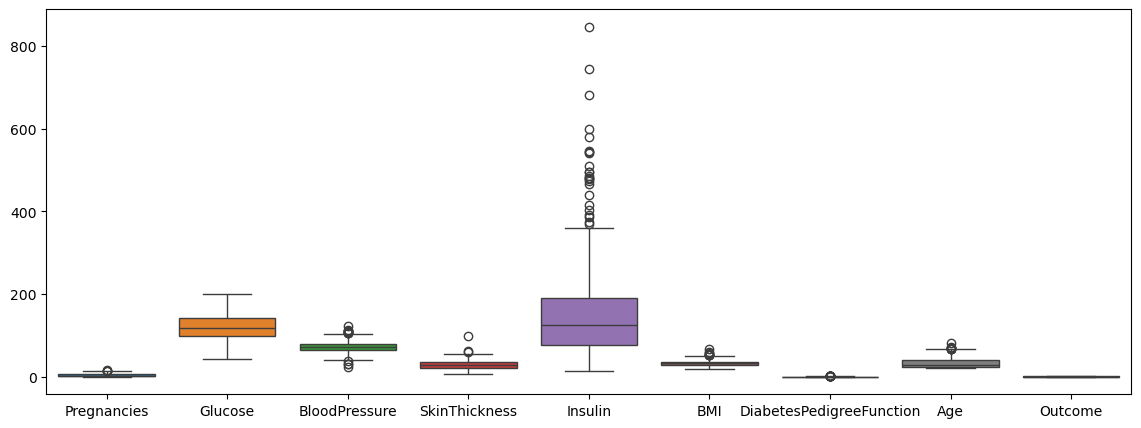

In [373]:
plt.figure(figsize=(14,5))
sns.boxplot(df)
plt.show()

In [374]:
 Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3- Q1
print(IQR)

Pregnancies                   5.0000
Glucose                      42.0000
BloodPressure                16.0000
SkinThickness                14.0000
Insulin                     113.7500
BMI                           9.1000
DiabetesPedigreeFunction      0.3825
Age                          17.0000
Outcome                       1.0000
dtype: float64


In [375]:
ul=Q3+1.5 *IQR
ll=Q1-1.5*IQR

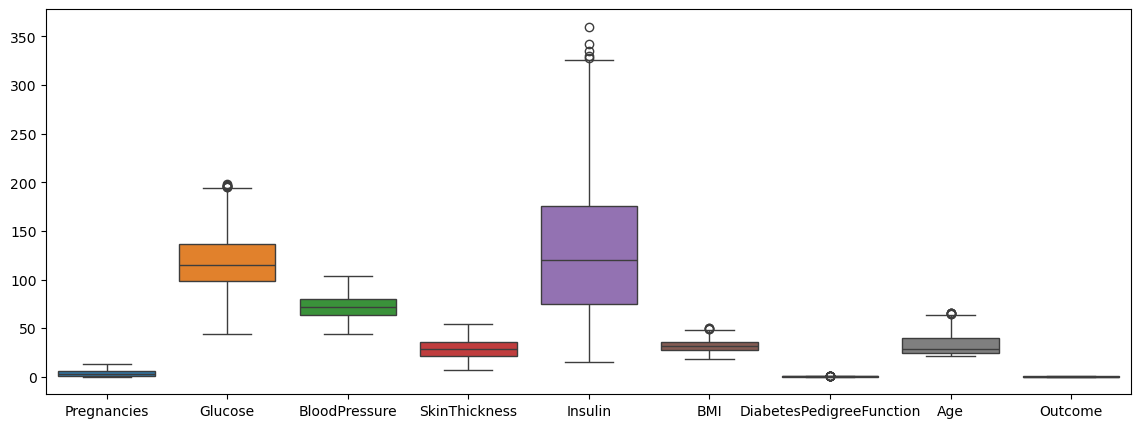

In [376]:
df = df[~((df < ll) | (df > ul)).any(axis=1)]
plt.figure(figsize=(14,5))
sns.boxplot(df)
plt.show()

In [377]:
df.shape

(684, 9)

In [378]:
#Divide the data frame into independent and dependent variables
X=df.loc[:, :'Age'].values
y=df.loc[:,'Outcome'].values

In [379]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [380]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=2)

In [381]:
 y_test.shape

(137,)

In [382]:
imputer = SimpleImputer(strategy='mean')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [383]:
for k in range(1, 20):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    accuracy = model.score(X_test, y_test)
    print(f'K: {k}\tAccuracy: {accuracy:.2%}')

K: 1	Accuracy: 70.07%
K: 2	Accuracy: 74.45%
K: 3	Accuracy: 75.91%
K: 4	Accuracy: 75.18%
K: 5	Accuracy: 73.72%
K: 6	Accuracy: 72.99%
K: 7	Accuracy: 77.37%
K: 8	Accuracy: 78.83%
K: 9	Accuracy: 76.64%
K: 10	Accuracy: 76.64%
K: 11	Accuracy: 75.18%
K: 12	Accuracy: 75.91%
K: 13	Accuracy: 75.18%
K: 14	Accuracy: 76.64%
K: 15	Accuracy: 75.91%
K: 16	Accuracy: 75.91%
K: 17	Accuracy: 78.10%
K: 18	Accuracy: 78.83%
K: 19	Accuracy: 80.29%


In [384]:
 model = KNeighborsClassifier(n_neighbors=5)

In [385]:
model.fit(X_train, y_train)

KNeighborsClassifier()

In [386]:
model.score(X_train,y_train)

0.8117001828153565

In [387]:
model.score(X_test,y_test)

0.7372262773722628

In [388]:
y_predict=model.predict(X_test)

In [389]:
cm = confusion_matrix(y_test, y_predict)

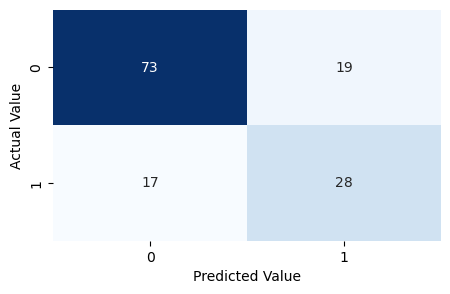

In [390]:
plt.figure(figsize=(5,3))
sns.heatmap(cm, annot=True, cmap='Blues', cbar=False, annot_kws={"fontsize":10})
plt.xlabel("Predicted Value")
plt.ylabel("Actual Value")
plt.show()

In [391]:
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       0.81      0.79      0.80        92
           1       0.60      0.62      0.61        45

    accuracy                           0.74       137
   macro avg       0.70      0.71      0.71       137
weighted avg       0.74      0.74      0.74       137

